# Cómo se entrena MIL-CREDA — un ejemplo completo sobre el toyset

Este cuaderno es un **tutorial**: muestra, celda por celda, cómo se entrena
MIL-CREDA sobre las tres familias del toyset (`lunas`, `toroide` y `rollo`) con
**una sola arquitectura**, el MLP con BatchNorm. No es el banco de resultados
publicado ni una búsqueda de hiperparámetros: cada pieza del entrenamiento queda
escrita a la vista para que se pueda leer, cambiar y volver a correr.

El recorrido es el del método:

1. **Los datos.** Cada dominio se corta en *bolsas* de instancias. Las bolsas de la
   **fuente** traen etiqueta; las del **blanco** se usan **sin etiqueta** para
   entrenar (su etiqueta sólo se lee al evaluar).
2. **El modelo.** Un codificador de instancias `θs` (el MLP con BatchNorm), la
   atención β que pondera las instancias de cada bolsa, la representación de bolsa
   y una cabeza lineal. Para el blanco hay un segundo codificador, `θt`.
3. **Fase 1 — supervisada en la fuente.** Se entrenan `θs`, la atención y la cabeza
   con la pérdida supervisada de bolsas (Ec. 21). Se elige la mejor época por el
   acierto en la **validación de la fuente**, se restauran esos pesos y se congelan.
4. **El ancho de banda congelado.** Con `θs` ya fijo se mide σ sobre la fuente
   (la mediana de distancias dentro de cada bolsa) y queda fijo para la fase 2.
5. **El clon.** `θt` arranca como una copia exacta de `θs`, **incluidos** los
   buffers de BatchNorm (`running_mean`, `running_var`).
6. **Fase 2 — adaptación.** Sólo se mueve `θt`, con el término global (Ecs. 32-37)
   y el local (Ecs. 30-31 y 38), ambos sopesados por la confianza del blanco. La
   pérdida supervisada se calcula como lectura pero no entra en el objetivo.
7. **Inferencia y gráficas.** Acierto en la prueba de la fuente (con `θs`) y del
   blanco (con `θt`), y el espacio latente de las bolsas de los dos dominios.

**Sobre el presupuesto.** Las épocas de este cuaderno son **didácticas**: alcanzan
para ver el flujo y que las curvas se muevan, no para afirmar convergencia. La
corrida completa del programa (`toy_run.FULL`) usa 100 épocas por fase y
hiperparámetros elegidos por búsqueda; acá se usan los valores declarados en
`config` sin buscar nada. Los números que imprime este cuaderno son los de **esta**
corrida corta y no deben leerse como el resultado publicado.

## Dónde está el repositorio

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


## Las herramientas

La celda de arriba resolvió `ROOT`, tanto si el cuaderno se abre en una máquina
local como si lo lanza un *runner* sobre un clon fijado a un commit. De acá en
adelante sólo se usa esa raíz.

Todo lo que entrena sale de `MIL_CREDA_Benchmark`: `toy_run` arma el material y el
modelo del toyset, `harness` da el muestreo balanceado y las métricas de acierto, y
`bags` parte cada dominio en sus roles (entrenamiento, validación y prueba). El
dispositivo es la CPU: en este toyset un paso procesa tres bolsas de 30 puntos y el
acelerador cuesta más de lo que ahorra (`toy_run.dispositivo_del_toyset` documenta
la razón).

In [2]:
import dataclasses
import math
import sys
import time

REPOSITORY = ROOT
sys.path.insert(0, str(REPOSITORY / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

from CREDA import toy_experiment
from MIL_CREDA_Benchmark import bags, config, harness, toy_run, tutorial_visuals

DISPOSITIVO = toy_run.dispositivo_del_toyset()
print("repositorio:", REPOSITORY)
print("revisión:   ", config.REVISION)
print("dispositivo:", DISPOSITIVO)

repositorio: /Users/diego/Proyectos/papersmith-ai/implementations/Domain_Adaptation
revisión:    research-concept-r34.md
dispositivo: cpu


## El presupuesto de esta corrida

Ésta es la única celda que hay que tocar para cambiar cuánto se entrena:

- `EPOCAS_1` es el **techo** de la fase 1; la corta antes la paciencia
  (`PACIENCIA_1` épocas sin mejorar el acierto de validación de la fuente).
- `EPOCAS_2` es el **largo** de la fase 2. El criterio de selección de la fase 2
  sólo puede elegir desde la época `toy_run.MIN_EPOCHS_2`, así que `EPOCAS_2` no
  puede ser menor.
- `SEMILLA` fija el sorteo de los datos, la inicialización y el muestreo.
- `BARRIDOS_W` es cuántos puntos tiene cada camino de la caminata de la
  confianza `w` (y cuántos cuadros su animación). No entrena nada.

Subir estos números acerca la corrida a la del programa completo y la hace más
lenta; bajarlos sirve para ensayar. Ninguno de los dos extremos cambia el flujo.

In [3]:
FAMILIAS = ("lunas", "toroide", "rollo")
NORMALIZACION = "batchnorm"
SEMILLA = 0
EPOCAS_1 = 60
PACIENCIA_1 = 15
EPOCAS_2 = 20
BARRIDOS_W = 24

In [4]:
# La arquitectura es una sola: el MLP con BatchNorm.
BACKBONE = toy_run.NORMALIZATIONS[NORMALIZACION]
# El único brazo del toyset: global + local, sopesado por confianza.
BRAZO = toy_run.TOY_ADAPTED
# El material del programa (81 bolsas de 30 instancias por dominio) con el
# presupuesto de arriba. Sólo cambian los largos; el material es el mismo.
ESCALA = dataclasses.replace(toy_run.PILOT, name="tutorial",
                             epochs_1=EPOCAS_1, epochs_2=EPOCAS_2,
                             patience_1=PACIENCIA_1)
# Los hiperparámetros declarados en `config`, sin búsqueda.
HIPER = toy_run.declared_hyper(ESCALA)

if ESCALA.epochs_2 < toy_run.MIN_EPOCHS_2:
    raise ValueError(f"EPOCAS_2 = {ESCALA.epochs_2}: la fase 2 necesita al menos "
                     f"{toy_run.MIN_EPOCHS_2} épocas para poder elegir una")

print("familias:       ", list(FAMILIAS))
print("normalización:  ", NORMALIZACION, "->", BACKBONE)
print("brazo:          ", BRAZO, "-", toy_run.TOY_ARMS_BY_ID[BRAZO]["label"])
print("épocas fase 1:  ", ESCALA.epochs_1, "(techo, paciencia", ESCALA.patience_1, ")")
print("épocas fase 2:  ", ESCALA.epochs_2)
print("tasas:          ", "lr1 =", HIPER["lr1"] or ESCALA.lr_1,
      " lr2 =", HIPER["lr2"] or ESCALA.lr_2)
print("bolsas por clase y rol:", ESCALA.realized_split()["bagsPerClass"],
      " instancias por bolsa:", ESCALA.instances_per_bag)
print("hiperparámetros declarados:", HIPER)

familias:        ['lunas', 'toroide', 'rollo']
normalización:   batchnorm -> mlp
brazo:           TGL - global + local, confidence weighting on, both coefficients 1
épocas fase 1:   60 (techo, paciencia 15 )
épocas fase 2:   20
tasas:           lr1 = 0.01  lr2 = 0.001
bolsas por clase y rol: {'train': 16, 'valid': 5, 'test': 6}  instancias por bolsa: 30
hiperparámetros declarados: {'kernelSigma': 36.135014304860874, 'attentionGamma': 0.0, 'attentionTemperature': 1.0, 'tauLocal': 1.0, 'lr1': None, 'weightDecay1': 0.0, 'dim': 16, 'lr2': None, 'weightDecay2': 0.0}


## Los datos: bolsas con etiqueta en la fuente, sin etiqueta en el blanco

`toy_run.build_family` dibuja los dos dominios de una familia —el blanco es una
versión perturbada de la fuente— y los corta en bolsas: cada bolsa es una banda
de una clase. `toy_run.material_for` los convierte en los `BagSet` que el
entrenamiento consume.

La figura es una sola, con un panel por familia. Cada panel superpone, en los
**mismos ejes**, la fuente con `x`, coloreada por su clase, y el blanco con `o`,
en gris, porque así lo ve el entrenamiento: **las etiquetas del blanco no
participan en ninguna pérdida**. Sólo se usan al final, para medir el acierto.


lunas    bolsas por dominio 81, instancias por bolsa 30, roles de la fuente train/valid/test = 48/15/18
toroide  bolsas por dominio 81, instancias por bolsa 30, roles de la fuente train/valid/test = 48/15/18
rollo    bolsas por dominio 81, instancias por bolsa 30, roles de la fuente train/valid/test = 48/15/18


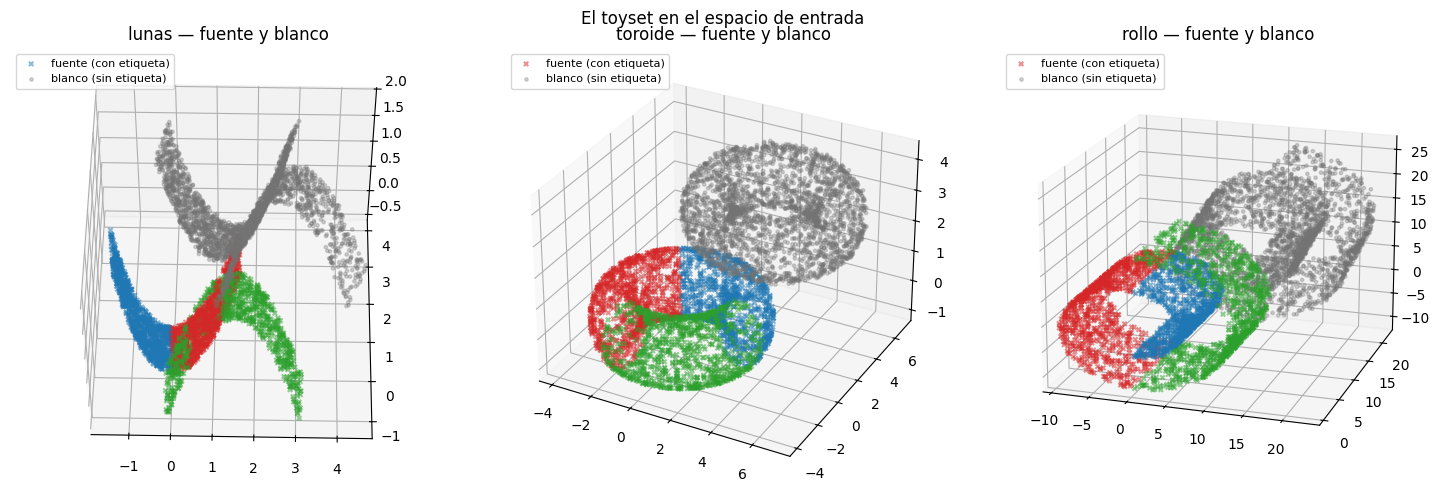

In [5]:
def material_de(nombre):
    familia = toy_run.build_family(nombre, SEMILLA, ESCALA)
    return familia, toy_run.material_for(familia, SEMILLA, ESCALA, BACKBONE)


def dibujar_entrada(entrada):
    figura = plt.figure(figsize=(15, 5))
    for columna, (nombre, datos) in enumerate(entrada.items(), 1):
        ax = figura.add_subplot(1, len(entrada), columna, projection="3d")
        colores = [toy_experiment.COL_DURA[int(c)] for c in datos["ys"]]
        ax.scatter(*datos["Xs"].T, c=colores, marker="x", s=10, alpha=0.5,
                   label="fuente (con etiqueta)")
        ax.scatter(*datos["Xt"].T, c="0.45", marker="o", s=6, alpha=0.3,
                   label="blanco (sin etiqueta)")
        puntos = np.concatenate([datos["Xs"], datos["Xt"]])
        bajo, alto = puntos.min(0), puntos.max(0)
        margen = 0.05 * (alto - bajo)
        ax.set_xlim(bajo[0] - margen[0], alto[0] + margen[0])
        ax.set_ylim(bajo[1] - margen[1], alto[1] + margen[1])
        ax.set_zlim(bajo[2] - margen[2], alto[2] + margen[2])
        ax.view_init(*toy_experiment.VISTA_DURA[nombre])
        ax.set_title(f"{nombre} — fuente y blanco")
        ax.legend(loc="upper left", fontsize=8)
    figura.suptitle("El toyset en el espacio de entrada")
    figura.tight_layout()
    return figura


INPUT_DATA = {}
for nombre in FAMILIAS:
    familia, material = material_de(nombre)
    INPUT_DATA[nombre] = {"Xs": familia.Xs, "ys": familia.ys, "Xt": familia.Xt}
    fuente = material["source"]
    print(f"{nombre:8s} bolsas por dominio {fuente.members.shape[0]}, "
          f"instancias por bolsa {fuente.members.shape[1]}, "
          f"roles de la fuente train/valid/test = "
          f"{len(fuente.train_idx)}/{len(fuente.valid_idx)}/{len(fuente.eval_idx)}")

FIGURAS = {}
FIGURAS["datos"] = INPUT_FIGURE = dibujar_entrada(INPUT_DATA)
plt.show()


## El modelo

`toy_run.build_arm` construye un `wiring.Arm` con la declaración del toyset. Sus
piezas:

- `encoder` es `θs`: el MLP con BatchNorm que lleva cada instancia (un punto 3D)
  a un vector latente.
- `V_R`, `b_R`, `v_R` son la atención β (Ecs. 15-17): ponderan las instancias de
  una bolsa. Junto con σ forman la representación de la bolsa (Ec. 19).
- `head` es la cabeza lineal que da los puntajes de clase de cada bolsa.
- `target_encoder` es `θt`, el codificador del blanco. Existe desde el principio
  pero la fase 1 no lo toca: se clona de `θs` antes de la fase 2.

σ, el ancho de banda del núcleo, hace falta ya en la fase 1, porque la atención
lo usa. Antes de entrenar se mide sobre las bolsas de entrenamiento de la fuente
(`toy_run.embedding_scales`, la mediana de distancias dentro de cada bolsa) y el
modelo de la fase 1 se construye con ese valor.

Ojo con un detalle: `config` tiene globales (bolsas por clase, instancias por
bolsa, el backbone) que el toyset ajusta mientras se construye y se entrena. Por
eso todo lo que construye o evalúa un modelo corre dentro de
`toy_run.material_bound`, que los ajusta y los restaura al salir.

In [6]:
def construir_modelo(material, hiper):
    return toy_run.build_arm(BRAZO, material, ESCALA, hiper, DISPOSITIVO, SEMILLA)


def modelo_de_fase_uno(material):
    # σ de arranque, medido sobre la fuente con el codificador sin entrenar.
    sonda = construir_modelo(material, HIPER)
    sigma = toy_run.embedding_scales(sonda, material["source"],
                                     material["source"].train_idx,
                                     DISPOSITIVO)["withinBag"]
    return construir_modelo(material, {**HIPER, "kernelSigma": sigma}), sigma


def lote(conjunto, posiciones):
    # Un lote de bolsas: x es (bolsas, instancias, 3) e y la clase de cada bolsa.
    elementos = [conjunto[int(i)] for i in posiciones]
    x = torch.stack([e[0] for e in elementos]).to(DISPOSITIVO)
    y = torch.tensor([e[1] for e in elementos], device=DISPOSITIVO)
    return x, y


# Un vistazo al modelo de `lunas`.
_familia, _material = material_de("lunas")
with toy_run.material_bound(_familia, ESCALA, BACKBONE, HIPER):
    _modelo, _sigma = modelo_de_fase_uno(_material)
    print(_modelo)
    for _bloque in ("encoder", "target_encoder", "head"):
        _n = sum(p.numel() for p in getattr(_modelo, _bloque).parameters())
        print(f"parámetros de {_bloque:15s} {_n}")
    print("parámetros de la atención      ",
          sum(getattr(_modelo, n).numel() for n in ("V_R", "b_R", "v_R")))
    print("σ de arranque:", round(_sigma, 4))
    _x, _y = lote(bags.roles(_material["source"])[0], range(config.BAGS_PER_STEP))
    _modelo.eval()
    with torch.no_grad():
        print("un lote de bolsas", tuple(_x.shape), "-> puntajes", tuple(_modelo(_x).shape))

Arm(
  (encoder): MLPEncoder(
    (net): Sequential(
      (0): Linear(in_features=3, out_features=32, bias=True)
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=32, out_features=32, bias=True)
      (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): Linear(in_features=32, out_features=16, bias=True)
    )
  )
  (head): Linear(in_features=16, out_features=3, bias=True)
  (target_encoder): MLPEncoder(
    (net): Sequential(
      (0): Linear(in_features=3, out_features=32, bias=True)
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=32, out_features=32, bias=True)
      (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): Linear(in_features=32, out_features=16, bias=True)
    )
  )
)
pará

## Fase 1: supervisada en la fuente

El optimizador recibe **todos los parámetros menos los de `θt`**. Cada paso toma
una bolsa de cada clase (`harness.balanced_batches`), calcula la pérdida
supervisada de bolsas (Ec. 21, `toy_run.supervised_loss`) y actualiza. Después de
cada paso se reimpone la restricción `‖v_R‖₁ ≤ 1` de la atención
(`project_constraints`).

Al final de cada época se mide el acierto en la **validación de la fuente**. Se
guarda el estado de la mejor época, se corta por paciencia, se restauran esos
pesos y se congelan (`requires_grad = False`). La prueba de la fuente y todo el
blanco quedan fuera de esta decisión.

In [7]:
def parametros_fuente(modelo):
    return [p for n, p in modelo.named_parameters()
            if not n.startswith("target_encoder.")]


def entrenar_fase_uno(modelo, fuente_train, fuente_valid, generador):
    parametros = parametros_fuente(modelo)
    optimizador = torch.optim.Adam(parametros, lr=HIPER["lr1"] or ESCALA.lr_1,
                                   weight_decay=HIPER["weightDecay1"])
    pasos = math.ceil(len(fuente_train) / config.BAGS_PER_STEP)
    historia = []
    mejor = {"acierto": -1.0, "epoca": 0, "estado": None}
    for epoca in range(1, ESCALA.epochs_1 + 1):
        modelo.train()
        perdidas = []
        for posiciones in harness.balanced_batches(fuente_train.targets, pasos,
                                                   generador):
            x, y = lote(fuente_train, posiciones)
            perdida = toy_run.supervised_loss(modelo, x, y)       # Ec. (21)
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
            modelo.project_constraints()                          # Ec. (15)
            perdidas.append(float(perdida.detach()))
        acierto = harness.accuracy(modelo, fuente_valid, DISPOSITIVO)
        historia.append({"epoca": epoca, "perdida": float(np.mean(perdidas)),
                         "aciertoValid": acierto})
        if acierto > mejor["acierto"]:
            mejor = {"acierto": acierto, "epoca": epoca,
                     "estado": toy_run.shared_phase_one_state(modelo)}
        if epoca - mejor["epoca"] >= ESCALA.patience_1:
            break
    # La mejor época vuelve, y la fuente queda congelada.
    modelo.load_state_dict(mejor["estado"], strict=False)
    for parametro in parametros:
        parametro.requires_grad_(False)
    modelo.eval()
    return {"historia": historia, "mejorEpoca": mejor["epoca"],
            "mejorAciertoValid": mejor["acierto"]}

## El σ congelado y el clon de la fuente al blanco

Con `θs` fijo se mide el σ que usará la fase 2: `toy_run.frozen_source_sigma`, la
mediana de distancias entre instancias de una misma bolsa sobre **todo** el
entrenamiento de la fuente. Lee sólo la fuente, así que nada del blanco puede
moverlo.

Después se construye el modelo de la fase 2 con ese σ, se le cargan los pesos de
la fase 1, se congela todo menos `θt` y se clona `θs` en `θt` con
`toy_run.copy_source_to_target`. Esa copia lleva también los buffers de BatchNorm:
sin ellos `θt` arrancaría con `running_mean = 0` y `running_var = 1` y no sería
la misma red. La celda comprueba que el clon es exacto.

In [8]:
def preparar_fase_dos(modelo_fuente, material):
    sigma = toy_run.frozen_source_sigma(modelo_fuente, material["source"],
                                        material["source"].train_idx,
                                        DISPOSITIVO)["sigma"]
    modelo = construir_modelo(material, {**HIPER, "kernelSigma": sigma})
    modelo.load_state_dict(toy_run.shared_phase_one_state(modelo_fuente),
                           strict=False)
    for parametro in parametros_fuente(modelo):
        parametro.requires_grad_(False)
    toy_run.copy_source_to_target(modelo)
    fuente = modelo.encoder.state_dict()
    blanco = modelo.target_encoder.state_dict()
    clon_exacto = (fuente.keys() == blanco.keys()
                   and all(torch.equal(fuente[k], blanco[k]) for k in fuente))
    return modelo, sigma, clon_exacto

## Fase 2: sólo se mueve `θt`

El optimizador recibe **únicamente** `modelo.target_encoder.parameters()`.
`toy_run.set_phase_two_modes` deja la fuente en `eval` —así sus estadísticas de
BatchNorm no se mueven— y `θt` en `train`.

En cada paso:

- `x, y` son bolsas de la **fuente** con su etiqueta: la etiqueta de la fuente
  define los bloques de clase del término global y la correspondencia local.
- `training_step` sortea por dentro bolsas del **blanco** sin mirar su etiqueta,
  las codifica con `θt` y arma el término global (Ecs. 32-37) y el local (Ecs.
  30-31, agregado por la Ec. 38), con los pesos de confianza del blanco (Ec. 24)
  y los dos coeficientes de la Ec. (39) fijos en `toy_run.FIXED_COEFFICIENT`.
- No se llama a `project_constraints()`: la restricción `‖v_R‖₁ ≤ 1` es de la
  atención, que en esta fase está congelada. Si `v_R` quedó sobre el borde al
  final de la fase 1, reproyectarlo lo movería por redondeo de punto flotante
  sin entrenar nada, y la fuente dejaría de estar congelada bit a bit.
- `toy_run.phase_two_objective` quita la pérdida supervisada del total: la fase 2
  minimiza global + local, y la supervisada queda como lectura.

Al final de cada época se lee `toy_run.effective_classes` (el número efectivo de
clases en las predicciones de `θt` sobre el blanco, sin etiquetas). Desde la
época `MIN_EPOCHS_2` se guarda la época con el máximo y se restaura al final.
Ninguna etiqueta del blanco entra en el objetivo ni en esta selección.

`observar` es opcional: si se pasa, se llama con el modelo antes del primer
paso (época 0, `θt` todavía igual a `θs`) y al cerrar cada época. Es lo que
arma la animación de la adaptación más abajo. Lee sobre una **copia** del
modelo, así que no mueve pesos, buffers de BatchNorm, modos `train`/`eval`
ni el generador: la fase 2 da lo mismo con observador y sin él.

In [9]:
def entrenar_fase_dos(modelo, fuente_train, generador, observar=None):
    toy_run.set_phase_two_modes(modelo)
    optimizador = torch.optim.Adam(modelo.target_encoder.parameters(),
                                   lr=HIPER["lr2"] or ESCALA.lr_2,
                                   weight_decay=HIPER["weightDecay2"])
    coeficiente = toy_run.FIXED_COEFFICIENT
    pasos_por_epoca = toy_run.steps_of_one_epoch(fuente_train.targets)
    historia, epocas = [], []
    mejor = {"cef": -math.inf, "epoca": -1, "estado": None}
    lotes = harness.balanced_batches(fuente_train.targets,
                                     ESCALA.epochs_2 * pasos_por_epoca, generador)
    if observar is not None:
        observar(modelo, 0)                                  # antes de adaptar
    for paso, posiciones in enumerate(lotes, start=1):
        x, y = lote(fuente_train, posiciones)
        optimizador.zero_grad()
        registro = modelo.training_step(x, y, coeficiente, generador,
                                        ramp_local=coeficiente)
        objetivo = toy_run.phase_two_objective(registro)          # global + local
        objetivo.backward()
        optimizador.step()
        # Sin `project_constraints()`: la restricción de la Ec. (15) es sobre
        # `v_R`, que en esta fase está congelado. Reproyectarlo no lo entrena y
        # sólo lo movería por redondeo.
        historia.append({"paso": paso, "objetivo": float(objetivo.detach()),
                         "global": registro["contributionGlobal"],
                         "local": registro["contributionLocal"],
                         "supervisadaLectura": registro["supervised"],
                         "confianzaBlanco": registro["targetConfidenceMean"]})
        if paso % pasos_por_epoca:
            continue
        epoca = paso // pasos_por_epoca
        cef = toy_run.effective_classes(modelo, DISPOSITIVO)
        epocas.append({"epoca": epoca, "cef": cef})
        if observar is not None:
            observar(modelo, epoca)
        if epoca >= toy_run.MIN_EPOCHS_2 and cef > mejor["cef"]:
            mejor = {"cef": cef, "epoca": epoca,
                     "estado": {k: v.detach().clone() for k, v in
                                modelo.target_encoder.state_dict().items()}}
    modelo.target_encoder.load_state_dict(mejor["estado"])
    toy_run.set_phase_two_modes(modelo)
    return {"historia": historia, "epocas": epocas, "pasosPorEpoca": pasos_por_epoca,
            "mejorEpoca": mejor["epoca"], "mejorCef": mejor["cef"]}

## Inferencia

Cada dominio se evalúa con su propio codificador y sobre su rol de **prueba**:

- la fuente con `θs` (`harness.accuracy`, que llama a `modelo(x)`);
- el blanco con `θt` (`harness.target_accuracy`, que llama a `modelo.score_target(x)`).

Acá, y sólo acá, se leen las etiquetas del blanco. También se guardan las
posiciones latentes de todas las bolsas de cada dominio (`toy_run.bag_positions`)
para dibujarlas.

In [10]:
def evaluar(modelo, material):
    _, _, fuente_test = bags.roles(material["source"])
    _, _, blanco_test = bags.roles(material["target"])
    resultado = {
        "aciertoFuente": harness.accuracy(modelo, fuente_test, DISPOSITIVO),
        "aciertoBlanco": harness.target_accuracy(modelo, blanco_test, DISPOSITIVO),
        "latenteFuente": toy_run.bag_positions(modelo, material["source"],
                                               DISPOSITIVO, "source"),
        "latenteBlanco": toy_run.bag_positions(modelo, material["target"],
                                               DISPOSITIVO, "target"),
    }
    toy_run.set_phase_two_modes(modelo)
    return resultado

## Las tres familias, de punta a punta

Para cada familia: material, σ de arranque, fase 1, σ congelado y clon, una
lectura del blanco **antes** de adaptar (con `θt` recién clonado, que es la
fuente tal cual), fase 2 e inferencia.

Además se mide lo que cada fase dice que hace, comparando los parámetros antes y
después de cada una:

- la fase 1 mueve la fuente y no toca `θt`;
- la fase 2 mueve `θt` y deja la fuente —parámetros y buffers de BatchNorm—
  idéntica bit a bit.

Durante la fase 2 un `tutorial_visuals.Trayectoria` toma una foto de las
bolsas del blanco en la época 0 y al cerrar cada época (a lo sumo
`toy_run.TRAJECTORY_FRAMES` épocas repartidas, más la 0): sus posiciones
latentes, la decisión de la cabeza y la confianza `w` de cada bolsa.

In [11]:
def vector_de(tensores):
    return torch.cat([t.detach().reshape(-1).double() for t in tensores]).clone()


def cambio(antes, despues):
    return float((despues - antes).norm())


def entrenar_familia(nombre):
    familia, material = material_de(nombre)
    inicio = time.perf_counter()
    with toy_run.material_bound(familia, ESCALA, BACKBONE, HIPER):
        fuente_train, fuente_valid, _ = bags.roles(material["source"])

        modelo_fuente, sigma_uno = modelo_de_fase_uno(material)
        fuente_0 = vector_de(parametros_fuente(modelo_fuente))
        blanco_0 = vector_de(modelo_fuente.target_encoder.parameters())
        fase_uno = entrenar_fase_uno(modelo_fuente, fuente_train, fuente_valid,
                                     torch.Generator().manual_seed(SEMILLA + 1))
        fuente_1 = vector_de(parametros_fuente(modelo_fuente))
        blanco_1 = vector_de(modelo_fuente.target_encoder.parameters())

        modelo, sigma_dos, clon_exacto = preparar_fase_dos(modelo_fuente, material)
        _, _, blanco_test = bags.roles(material["target"])
        acierto_blanco_antes = harness.target_accuracy(modelo, blanco_test,
                                                       DISPOSITIVO)
        fuente_2 = vector_de(parametros_fuente(modelo))
        buffers_2 = vector_de(modelo.encoder.buffers())
        blanco_2 = vector_de(modelo.target_encoder.parameters())
        trayectoria = tutorial_visuals.Trayectoria(material, DISPOSITIVO,
                                                   ESCALA.epochs_2)
        fase_dos = entrenar_fase_dos(modelo, fuente_train,
                                     torch.Generator().manual_seed(SEMILLA + 2),
                                     observar=trayectoria)
        evaluacion = evaluar(modelo, material)

        chequeos = {
            "fuenteMovidaFaseUno": cambio(fuente_0, fuente_1),
            "blancoMovidoFaseUno": cambio(blanco_0, blanco_1),
            "clonExacto": clon_exacto,
            "fuenteMovidaFaseDos": cambio(fuente_2, vector_de(parametros_fuente(modelo))),
            "buffersFuenteMovidosFaseDos": cambio(buffers_2,
                                                  vector_de(modelo.encoder.buffers())),
            "blancoMovidoFaseDos": cambio(blanco_2,
                                          vector_de(modelo.target_encoder.parameters())),
        }
        capas_bn = sum(isinstance(m, torch.nn.BatchNorm1d) for m in modelo.modules())
    return {"modelo": modelo, "sigmaFaseUno": sigma_uno, "sigmaFaseDos": sigma_dos,
            "faseUno": fase_uno, "faseDos": fase_dos, "chequeos": chequeos,
            "capasBatchNorm": capas_bn,
            "trayectoria": trayectoria.como_dict(),
            "familia": familia, "material": material,
            "evaluacion": {**evaluacion, "aciertoBlancoAntes": acierto_blanco_antes},
            "segundos": time.perf_counter() - inicio}


RESULTADOS = {}
for nombre in FAMILIAS:
    RESULTADOS[nombre] = entrenar_familia(nombre)
    r = RESULTADOS[nombre]
    print(f"--- {nombre} ({r['segundos']:.1f} s en esta máquina)")
    print(f"  fase 1: {len(r['faseUno']['historia'])} épocas, mejor época "
          f"{r['faseUno']['mejorEpoca']}, acierto valid fuente "
          f"{r['faseUno']['mejorAciertoValid']:.3f}")
    print(f"  σ de arranque {r['sigmaFaseUno']:.4f}  ->  σ congelado {r['sigmaFaseDos']:.4f}")
    print(f"  fase 2: {len(r['faseDos']['historia'])} pasos, época elegida "
          f"{r['faseDos']['mejorEpoca']} (cef {r['faseDos']['mejorCef']:.3f})")
    for clave, valor in r["chequeos"].items():
        print(f"  {clave:28s} {valor}")

--- lunas (3.8 s en esta máquina)
  fase 1: 17 épocas, mejor época 2, acierto valid fuente 0.933
  σ de arranque 0.9793  ->  σ congelado 0.5488
  fase 2: 320 pasos, época elegida 19 (cef 2.784)
  fuenteMovidaFaseUno          4.303663167981825
  blancoMovidoFaseUno          0.0
  clonExacto                   True
  fuenteMovidaFaseDos          0.0
  buffersFuenteMovidosFaseDos  0.0
  blancoMovidoFaseDos          1.441561132732513


--- toroide (3.9 s en esta máquina)
  fase 1: 16 épocas, mejor época 1, acierto valid fuente 1.000
  σ de arranque 1.5606  ->  σ congelado 1.8915
  fase 2: 320 pasos, época elegida 17 (cef 2.984)
  fuenteMovidaFaseUno          4.866098690132349
  blancoMovidoFaseUno          0.0
  clonExacto                   True
  fuenteMovidaFaseDos          0.0
  buffersFuenteMovidosFaseDos  0.0
  blancoMovidoFaseDos          1.054854015246727


--- rollo (4.3 s en esta máquina)
  fase 1: 23 épocas, mejor época 8, acierto valid fuente 1.000
  σ de arranque 1.2167  ->  σ congelado 0.8829
  fase 2: 320 pasos, época elegida 5 (cef 2.996)
  fuenteMovidaFaseUno          7.428180910348506
  blancoMovidoFaseUno          0.0
  clonExacto                   True
  fuenteMovidaFaseDos          0.0
  buffersFuenteMovidosFaseDos  0.0
  blancoMovidoFaseDos          0.6940578736348182


## Las curvas y el espacio latente

Arriba, por familia, la fase 1 (pérdida de entrenamiento y acierto de validación
de la fuente) y la fase 2 por paso (los términos global y local, su suma, que es
el objetivo, y la supervisada como lectura). La línea vertical marca la época que
eligió la fase 2.

Abajo, las bolsas de los dos dominios en el espacio latente después de adaptar,
proyectadas a 2D por componentes principales: círculos para la fuente (`θs`) y
cruces para el blanco (`θt`), con el color de su clase verdadera.

Con un presupuesto corto las curvas pueden no haberse aplanado todavía: eso es lo
esperable y no es un defecto del método.

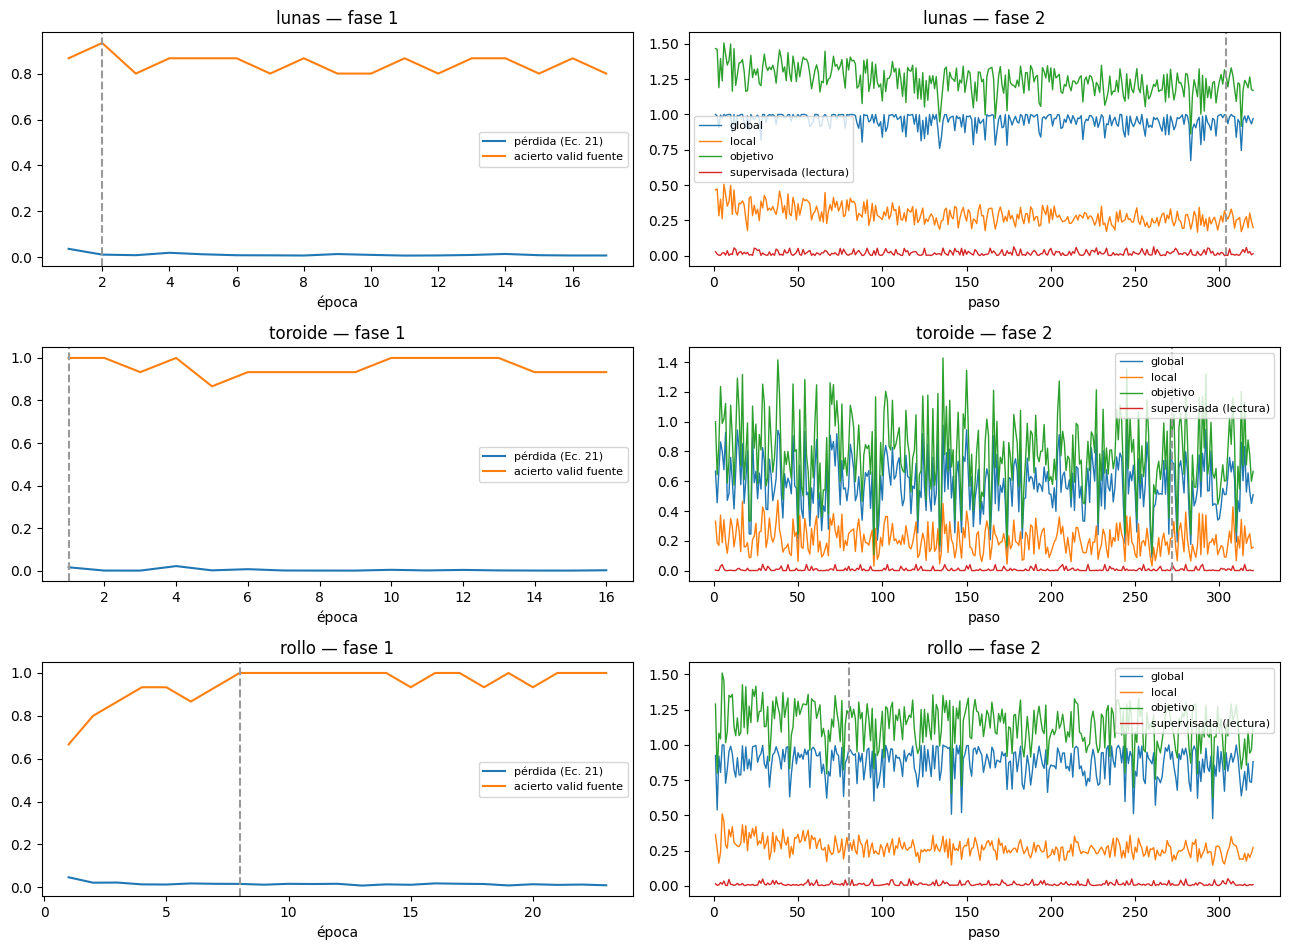

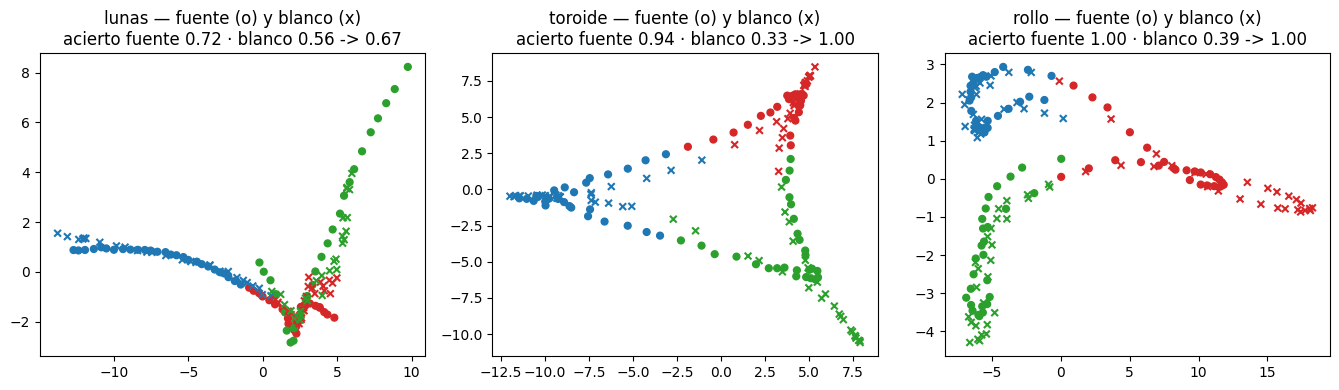

familia     fuente  blanco antes  blanco después
lunas        0.722         0.556           0.667
toroide      0.944         0.333           1.000
rollo        1.000         0.389           1.000


In [12]:
FIGURAS["curvas"], _ejes = plt.subplots(len(FAMILIAS), 2,
                                        figsize=(13, 3.2 * len(FAMILIAS)),
                                        squeeze=False)
for fila, nombre in enumerate(FAMILIAS):
    r = RESULTADOS[nombre]
    uno, dos = r["faseUno"]["historia"], r["faseDos"]["historia"]
    ax = _ejes[fila, 0]
    ax.plot([h["epoca"] for h in uno], [h["perdida"] for h in uno], label="pérdida (Ec. 21)")
    ax.plot([h["epoca"] for h in uno], [h["aciertoValid"] for h in uno], label="acierto valid fuente")
    ax.axvline(r["faseUno"]["mejorEpoca"], color="0.6", ls="--")
    ax.set_title(f"{nombre} — fase 1")
    ax.set_xlabel("época")
    ax.legend(fontsize=8)
    ax = _ejes[fila, 1]
    pasos = [h["paso"] for h in dos]
    for clave, etiqueta in (("global", "global"), ("local", "local"),
                            ("objetivo", "objetivo"),
                            ("supervisadaLectura", "supervisada (lectura)")):
        ax.plot(pasos, [h[clave] for h in dos], label=etiqueta, lw=1)
    ax.axvline(r["faseDos"]["mejorEpoca"] * r["faseDos"]["pasosPorEpoca"],
               color="0.6", ls="--")
    ax.set_title(f"{nombre} — fase 2")
    ax.set_xlabel("paso")
    ax.legend(fontsize=8)
FIGURAS["curvas"].tight_layout()
plt.show()

FIGURAS["latente"], _ejes = plt.subplots(1, len(FAMILIAS),
                                         figsize=(4.5 * len(FAMILIAS), 4),
                                         squeeze=False)
for columna, nombre in enumerate(FAMILIAS):
    e = RESULTADOS[nombre]["evaluacion"]
    fuente, blanco = e["latenteFuente"], e["latenteBlanco"]
    juntas = np.concatenate([fuente["positions"], blanco["positions"]])
    centro = juntas.mean(axis=0)
    _, _, ejes_pca = np.linalg.svd(juntas - centro, full_matrices=False)
    ax = _ejes[0, columna]
    for dominio, marca in ((fuente, "o"), (blanco, "x")):
        plano = (dominio["positions"] - centro) @ ejes_pca[:2].T
        ax.scatter(plano[:, 0], plano[:, 1], marker=marca, s=24,
                   c=[toy_experiment.COL_DURA[int(c)] for c in dominio["classes"]])
    ax.set_title(f"{nombre} — fuente (o) y blanco (x)\n"
                 f"acierto fuente {e['aciertoFuente']:.2f} · blanco "
                 f"{e['aciertoBlancoAntes']:.2f} -> {e['aciertoBlanco']:.2f}")
FIGURAS["latente"].tight_layout()
plt.show()

print(f"{'familia':9s} {'fuente':>8s} {'blanco antes':>13s} {'blanco después':>15s}")
for nombre in FAMILIAS:
    e = RESULTADOS[nombre]["evaluacion"]
    print(f"{nombre:9s} {e['aciertoFuente']:8.3f} {e['aciertoBlancoAntes']:13.3f} "
          f"{e['aciertoBlanco']:15.3f}")

## La adaptación, época por época

Esta animación sale de **esta** corrida: cada cuadro es una foto que tomó el
observador de la fase 2, no una interpolación entre el principio y el final. El
cuadro 0 es `θt` recién clonado (el blanco visto con el codificador de la
fuente) y los siguientes son el cierre de cada época capturada.

- **Izquierda:** las bolsas en el espacio latente, con el color de su clase
  **real**. La base PCA se ajusta una vez sobre la fuente, que no se mueve, y
  los límites son los mismos en todos los cuadros: lo que se ve moverse es el
  blanco. Las etiquetas del blanco sólo pintan este panel.
- **Centro:** la misma nube, con el color de la **decisión** de la cabeza; la
  opacidad y el tamaño de cada bolsa del blanco son su confianza `w` (Ec. 24).
  Una bolsa de un color sobre el rombo de otro es una bolsa mal decidida.
- **Derecha:** por época, la confianza media del blanco, su acierto (sólo como
  lectura) y el objetivo global + local que minimiza la fase 2.


lunas: épocas capturadas [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


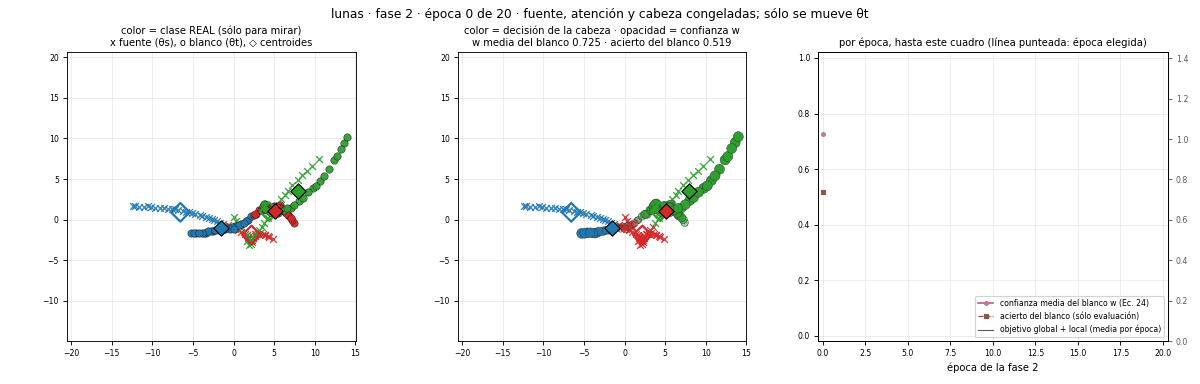

toroide: épocas capturadas [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


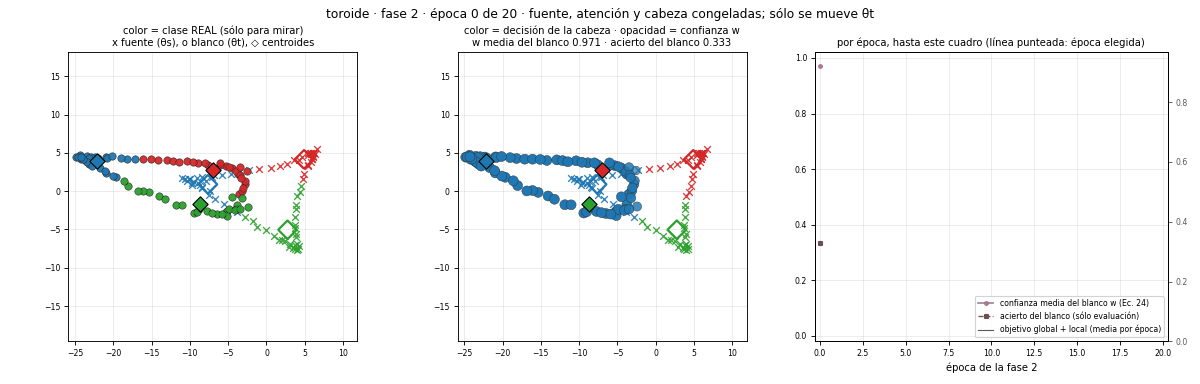

rollo: épocas capturadas [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


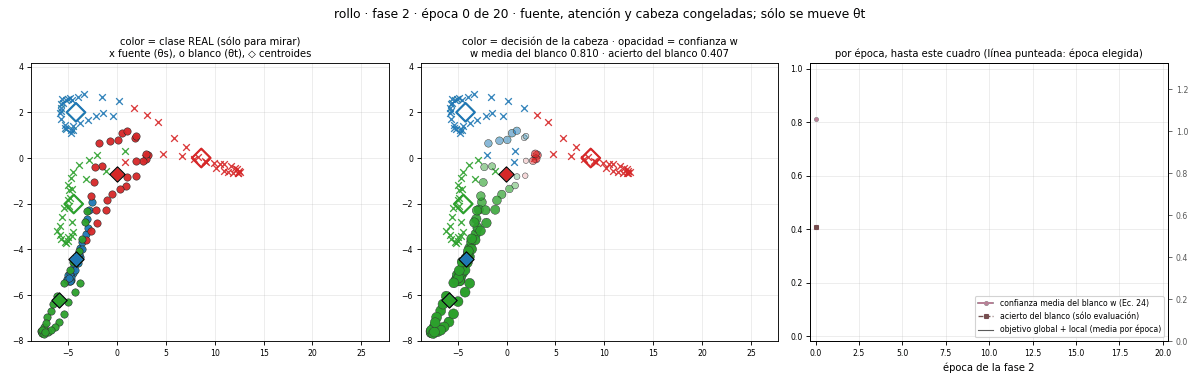

In [13]:
ANIMACIONES = {nombre: {} for nombre in FAMILIAS}
for nombre in FAMILIAS:
    r = RESULTADOS[nombre]
    ANIMACIONES[nombre]["adaptacion"] = tutorial_visuals.gif_de_adaptacion(
        r["trayectoria"], r["faseDos"], nombre)
    print(f"{nombre}: épocas capturadas {r['trayectoria']['epocas']}")
    display(Image(data=ANIMACIONES[nombre]["adaptacion"], format="gif"))


## La confianza `w` a lo largo de un camino construido

La confianza de una bolsa del blanco es `w_j = 1 − Ĥ₂(g_j)/ln C` (Ec. 24): vale
cerca de 0 donde la cabeza duda entre clases y cerca de 1 donde el posterior de
bolsa `g_j` (Ec. 20) se concentra en una. Es el peso con el que cada bolsa del
blanco entra en los términos global y local.

Para verla, `toy_run.caminata_de_w` toma el modelo **ya entrenado** y elige,
sin mirar etiquetas del blanco, tres bolsas del blanco indecisas: entre las
clases 0 y 1, entre 1 y 2, y entre las tres. Si ninguna bolsa tiene ese par
como sus dos clases más probables, la elección se relaja y la celda lo dice:
esa bolsa no está realmente sobre esa frontera. Cada una camina en línea recta,
en el espacio de representación de bolsa, hasta el centro de una clase de la
**fuente**, y en cada punto del camino se lee `w` con la cabeza congelada.

**El eje es el barrido, no el tiempo de entrenamiento.** Nada se optimiza
durante la caminata: es una pregunta a la cabeza por posiciones construidas.
La animación de arriba muestra lo que hizo el optimizador; ésta muestra cómo
responde `w` a la distancia a una frontera de decisión. A la izquierda, los
caminos sobre la nube de la fuente (el `+` es la frontera exacta de la cabeza,
el círculo hueco la bolsa real de la que sale); a la derecha, la curva de `w`
hasta el barrido del cuadro.


lunas    frontera-0-1     -> clase 0: w 0.136 -> 0.999
lunas    frontera-1-2     -> clase 2: w 0.369 -> 0.838
lunas    frontera-triple  -> clase 1: w 0.202 -> 0.728


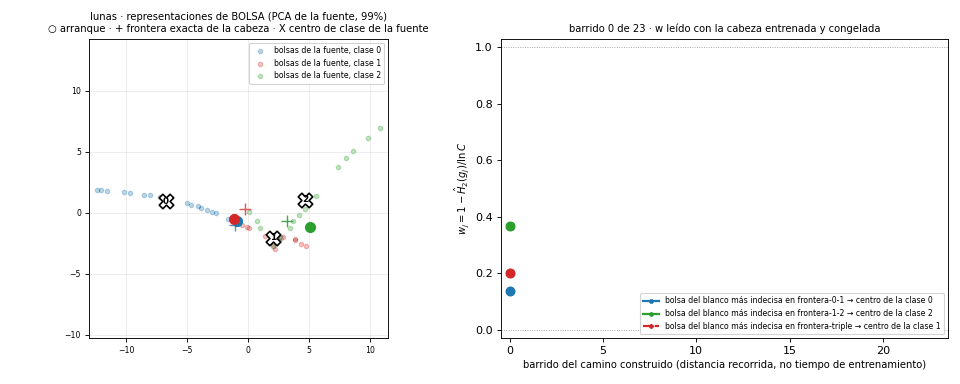

toroide  frontera-0-1     -> clase 0: w 0.715 -> 0.999
toroide  frontera-1-2     -> clase 2: w 0.341 -> 0.987
toroide  frontera-triple  -> clase 1: w 0.469 -> 0.993


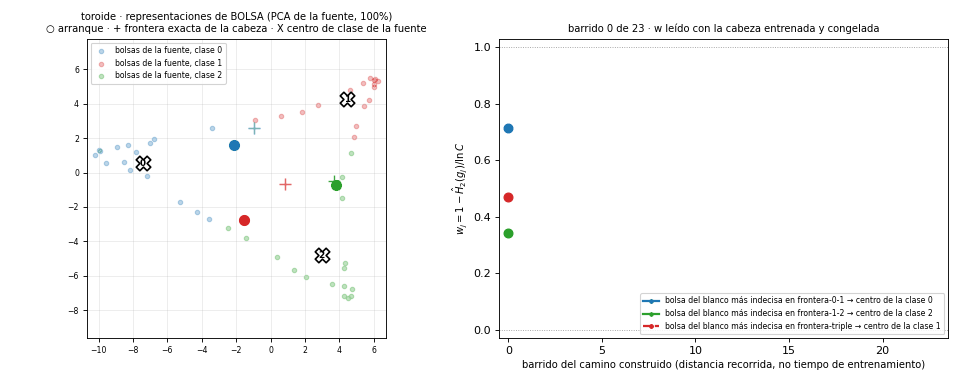

rollo    frontera-0-1     -> clase 0: w 0.337 -> 0.747
rollo    frontera-1-2     -> clase 2: w 1.000 -> 0.771
rollo    frontera-triple  -> clase 1: w 0.291 -> 0.999


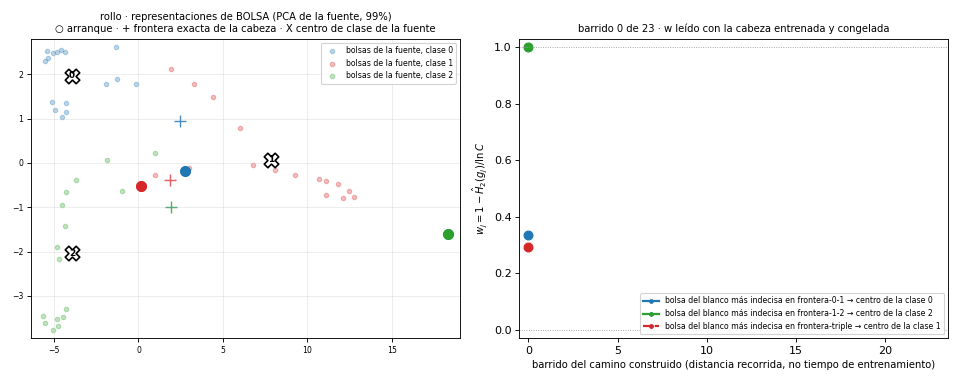

In [14]:
for nombre in FAMILIAS:
    r = RESULTADOS[nombre]
    with toy_run.material_bound(r["familia"], ESCALA, BACKBONE, HIPER):
        r["caminataW"] = toy_run.caminata_de_w(
            r["modelo"], r["material"]["source"], r["material"]["target"],
            DISPOSITIVO, barridos=BARRIDOS_W)
    caminata = r["caminataW"]
    ANIMACIONES[nombre]["w"] = tutorial_visuals.gif_de_caminata(caminata, nombre)
    for arranque in caminata["arranques"]:
        (destino, inicial), = caminata["wInicial"][arranque].items()
        final = caminata["wFinal"][arranque][destino]
        relajada = (" (ninguna bolsa tenía ese par arriba: elección relajada)"
                    if caminata["eleccionRelajada"][arranque] else "")
        print(f"{nombre:8s} {arranque:16s} -> clase {destino}: "
              f"w {inicial:.3f} -> {final:.3f}{relajada}")
    display(Image(data=ANIMACIONES[nombre]["w"], format="gif"))


## Para seguir

- **Cómo leer la tabla.** Los aciertos se miden sobre el rol de prueba (18 bolsas
  por dominio), así que cada uno se mueve de a 1/18. Con una semilla y un
  presupuesto corto la diferencia entre "blanco antes" y "blanco después" puede ir
  en cualquier dirección; una conclusión sobre el método necesita varias semillas,
  el presupuesto completo y los hiperparámetros elegidos por búsqueda.
- **Qué tocar.** El presupuesto está en una sola celda. Las tasas y demás
  hiperparámetros salen de `toy_run.declared_hyper`; para probar otros valores
  basta con cambiar `HIPER` antes de la celda que entrena las familias.
- **Qué no cambia.** La selección de la fase 1 lee sólo la validación de la
  fuente, la fuente y la cabeza quedan congeladas durante la fase 2, `θt` arranca
  como clon exacto de `θs` y ninguna etiqueta del blanco entra en el objetivo.
- Este cuaderno no escribe nada en disco: todo queda en `RESULTADOS`, `FIGURAS`
  y `ANIMACIONES` (los GIF viven en memoria y en las salidas del cuaderno).